# WildSight: YOLO-Based Detection of African Wildlife
**CS4045 Deep Learning for Perception, Option B (Object Detection)**

Dataset: Ultralytics African Wildlife (buffalo, elephant, rhino, zebra) | Model: YOLO11m fine-tuned from COCO weights

In [ ]:
MODEL = "yolo11m.pt"
DATA = "african-wildlife.yaml"
EPOCHS = 100
PATIENCE = 20
IMGSZ = 640
BATCH = 16
SEED = 0

In [ ]:
!pip -q install -U ultralytics gradio
import os, shutil, random, time, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt, torch
from PIL import Image
from ultralytics import YOLO
from IPython.display import display
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.width', 200)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
RES = Path('/content/results'); RES.mkdir(exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 1. Dataset download and indexing

In [ ]:
from ultralytics.data.utils import check_det_dataset
D = check_det_dataset(DATA)
NAMES = {int(k): v for k, v in D['names'].items()} if isinstance(D['names'], dict) else dict(enumerate(D['names']))
ID = {v.lower(): k for k, v in NAMES.items()}
CLASS_IDS = sorted(NAMES)
first = lambda p: p[0] if isinstance(p, (list, tuple)) else p
SPLIT_DIR = {k: str(first(D[k])) for k in ['train', 'val', 'test']}
EXT = {'.jpg', '.jpeg', '.png', '.bmp'}
list_imgs = lambda d: sorted(str(p) for p in Path(d).glob('*') if p.suffix.lower() in EXT)
label_path = lambda ip: str(ip).replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
IMGS = {k: list_imgs(v) for k, v in SPLIT_DIR.items()}

def read_gt(ip, W, H):
    out = []
    if not os.path.exists(label_path(ip)): return out
    for l in open(label_path(ip)):
        p = l.split()
        if len(p) < 5: continue
        c, x, y, w, h = int(p[0]), *map(float, p[1:5])
        out.append((c, (x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H))
    return out

SIZES = {ip: Image.open(ip).size for files in IMGS.values() for ip in files}
GT = {ip: read_gt(ip, *SIZES[ip]) for ip in SIZES}
print({k: len(v) for k, v in IMGS.items()})
print(NAMES)


WARNING ⚠️ Dataset 'african-wildlife.yaml' images not found, missing path '/content/datasets/african-wildlife/images/val'
Unzipping /content/datasets/african-wildlife.zip to /content/datasets/african-wildlife...: 100% ━━━━━━━━━━━━ 3018/3018 1.6Kfiles/s 1.9s
Dataset download success ✅ (3.6s), saved to /content/datasets

{'train': 1052, 'val': 225, 'test': 227}
{0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}


## 2. Dataset overview

In [ ]:
rows = []
for s, files in IMGS.items():
    ws = [SIZES[ip][0] for ip in files]; hs = [SIZES[ip][1] for ip in files]
    n_obj = sum(len(GT[ip]) for ip in files)
    rows.append({'split': s, 'images': len(files), 'objects': n_obj, 'objects per image': round(n_obj/len(files), 2),
                 'mean width': int(np.mean(ws)), 'mean height': int(np.mean(hs)),
                 'min width': min(ws), 'max width': max(ws), 'empty images': sum(len(GT[ip]) == 0 for ip in files)})
overview = pd.DataFrame(rows).set_index('split')
total = overview[['images', 'objects']].sum()
display(overview); print("Total images:", int(total['images']), "| Total annotated animals:", int(total['objects']))
overview.to_csv(RES/'dataset_overview.csv')

,images,objects,objects per image,mean width,mean height,min width,max width,empty images
split,,,,,,,,
train,1052,1931,1.84,814,557,99,1920,0
val,225,379,1.68,751,521,130,1920,0
test,227,375,1.65,819,577,150,1920,0


Total images: 1504 | Total annotated animals: 2685


## 3. Class distribution

,train,val,test,total,share of all (%)
buffalo,399,89,66,554,20.6
elephant,558,91,99,748,27.9
rhino,399,85,75,559,20.8
zebra,575,114,135,824,30.7


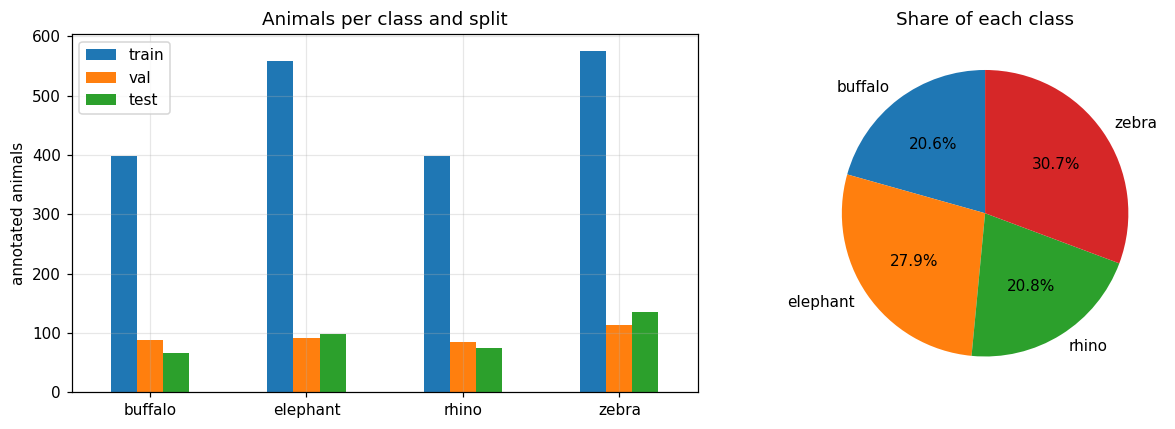

In [ ]:
cnt = pd.DataFrame({s: Counter(g[0] for ip in files for g in GT[ip]) for s, files in IMGS.items()}).fillna(0).astype(int)
cnt.index = [NAMES[i] for i in cnt.index]; cnt = cnt.loc[[NAMES[i] for i in CLASS_IDS]]
cnt['total'] = cnt.sum(axis=1); cnt['share of all (%)'] = (100*cnt['total']/cnt['total'].sum()).round(1)
display(cnt); cnt.to_csv(RES/'class_distribution.csv')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cnt[['train', 'val', 'test']].plot(kind='bar', ax=ax[0], rot=0); ax[0].set_title('Animals per class and split'); ax[0].set_ylabel('annotated animals')
ax[1].pie(cnt['total'], labels=cnt.index, autopct='%1.1f%%', startangle=90); ax[1].set_title('Share of each class'); ax[1].grid(False)
plt.tight_layout(); plt.savefig(RES/'class_distribution.png', bbox_inches='tight'); plt.show()

## 4. Bounding box statistics

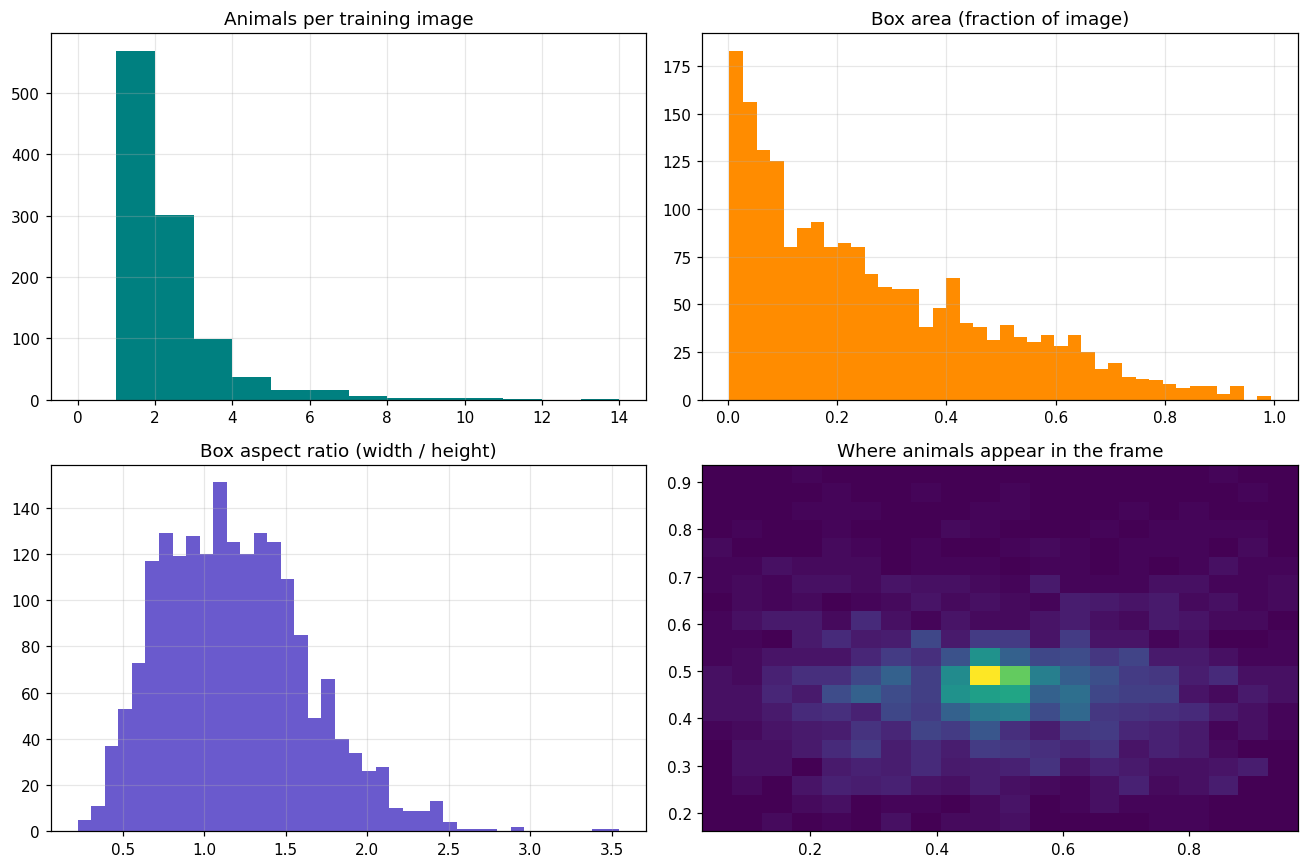

size,small,medium,large
class,,,
buffalo,36,130,233
elephant,144,229,185
rhino,16,148,235
zebra,133,262,180


,w,h,area,aspect
class,,,,
buffalo,0.523,0.605,0.360,1.268
elephant,0.352,0.483,0.210,1.073
rhino,0.507,0.600,0.330,1.401
zebra,0.353,0.486,0.207,1.107


In [ ]:
size_cat = lambda a: 'small' if a < 0.05 else 'medium' if a < 0.25 else 'large'
box_rows = []
for ip in IMGS['train']:
    W, H = SIZES[ip]
    for c, x1, y1, x2, y2 in GT[ip]:
        w, h = x2-x1, y2-y1
        box_rows.append({'class': NAMES[c], 'w': w/W, 'h': h/H, 'area': w*h/(W*H), 'aspect': w/max(h, 1e-6),
                         'cx': (x1+x2)/2/W, 'cy': (y1+y2)/2/H, 'size': size_cat(w*h/(W*H))})
boxes = pd.DataFrame(box_rows)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].hist([len(GT[ip]) for ip in IMGS['train']], bins=range(0, 15), color='teal'); ax[0, 0].set_title('Animals per training image')
ax[0, 1].hist(boxes['area'], bins=40, color='darkorange'); ax[0, 1].set_title('Box area (fraction of image)')
ax[1, 0].hist(boxes['aspect'].clip(0, 4), bins=40, color='slateblue'); ax[1, 0].set_title('Box aspect ratio (width / height)')
h2 = ax[1, 1].hist2d(boxes['cx'], 1-boxes['cy'], bins=20, cmap='viridis'); ax[1, 1].set_title('Where animals appear in the frame'); ax[1, 1].grid(False)
plt.tight_layout(); plt.savefig(RES/'box_statistics.png', bbox_inches='tight'); plt.show()
size_table = pd.crosstab(boxes['class'], boxes['size'])[['small', 'medium', 'large']]
display(size_table)
display(boxes.groupby('class')[['w', 'h', 'area', 'aspect']].mean().round(3))

## 5. Sample images for every class

In [ ]:
def draw_gt(ip):
    im = cv2.imread(ip); H, W = im.shape[:2]; t = max(2, W//300); fs = max(0.6, W/1000)
    for c, x1, y1, x2, y2 in GT[ip]:
        cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), (0, 200, 0), t)
        cv2.putText(im, NAMES[c], (int(x1), max(18, int(y1)-8)), cv2.FONT_HERSHEY_SIMPLEX, fs, (0, 255, 255), t)
    return im[..., ::-1]

fig, axs = plt.subplots(len(CLASS_IDS), 3, figsize=(14, 3.8*len(CLASS_IDS)))
for r_, c in enumerate(CLASS_IDS):
    cand = [ip for ip in IMGS['train'] if any(g[0] == c for g in GT[ip])]
    for a, ip in zip(axs[r_], random.sample(cand, 3)):
        a.imshow(draw_gt(ip)); a.axis('off'); a.set_title(NAMES[c])
plt.tight_layout(); plt.savefig(RES/'samples_per_class.png', bbox_inches='tight'); plt.show()

## 6. Evaluation toolkit

In [ ]:
def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter/ua if ua > 0 else 0

def match(gt, preds, thr=0.5):
    used, tp, fp = set(), [], []
    for q in sorted(preds, key=lambda q: -q[1]):
        best_v, bi = 0, -1
        for j, g in enumerate(gt):
            if j in used or g[0] != q[0]: continue
            v = iou(q[2:], g[1:])
            if v > best_v: best_v, bi = v, j
        if best_v >= thr: used.add(bi); tp.append(q)
        else: fp.append(q)
    return tp, fp, [g for j, g in enumerate(gt) if j not in used]

def records_for(PRED, imgs, cid, thr=0.5):
    rec, ngt = [], 0
    for ip in imgs:
        gt = [g for g in GT[ip] if g[0] == cid]; pr = [q for q in PRED[ip] if q[0] == cid]
        ngt += len(gt); tp, fp, _ = match(gt, pr, thr)
        rec += [(q[1], 1) for q in tp] + [(q[1], 0) for q in fp]
    return sorted(rec, key=lambda t: -t[0]), ngt

def pr_arrays(rec, ngt):
    n = max(ngt, 1)
    tpc = np.cumsum([t[1] for t in rec]); fpc = np.cumsum([1-t[1] for t in rec])
    return np.array([t[0] for t in rec]), tpc/np.maximum(tpc+fpc, 1e-9), tpc/n

def average_precision(P, R):
    mr, mp = np.r_[0, R, 1], np.r_[0, P, 0]
    for i in range(len(mp)-2, -1, -1): mp[i] = max(mp[i], mp[i+1])
    return float(np.sum((mr[1:]-mr[:-1])*mp[1:]))

def ap_for(PRED, imgs, cid, thr=0.5):
    rec, ngt = records_for(PRED, imgs, cid, thr); _, P, R = pr_arrays(rec, ngt)
    return average_precision(P, R)

COCO_IDS = {'elephant': 20, 'zebra': 22}
COCO_TO_OURS = {COCO_IDS[n]: ID[n] for n in COCO_IDS}

def make_fn(m, coco=False):
    def fn(ip):
        kw = dict(classes=list(COCO_IDS.values())) if coco else {}
        r = m.predict(ip, conf=0.001, iou=0.6, imgsz=IMGSZ, verbose=False, max_det=300, **kw)[0]
        out = []
        for b in r.boxes:
            c = int(b.cls)
            out.append((COCO_TO_OURS[c] if coco else c, float(b.conf), *map(float, b.xyxy[0].tolist())))
        return out
    return fn

def confusion(PRED, imgs, conf, thr=0.5):
    nc = len(CLASS_IDS); cm = np.zeros((nc+1, nc+1), int)
    for ip in imgs:
        gt = GT[ip]; used = set()
        for q in sorted([q for q in PRED[ip] if q[1] >= conf], key=lambda q: -q[1]):
            best_v, bj = 0, -1
            for j, g in enumerate(gt):
                if j in used: continue
                v = iou(q[2:], g[1:])
                if v > best_v: best_v, bj = v, j
            if best_v >= thr: used.add(bj); cm[gt[bj][0], q[0]] += 1
            else: cm[nc, q[0]] += 1
        for j, g in enumerate(gt):
            if j not in used: cm[g[0], nc] += 1
    return cm

def error_types(PRED, imgs, conf):
    cnt = {'Correct detection': 0, 'Wrong species': 0, 'Poor box / duplicate': 0, 'False alarm (background)': 0, 'Missed animal': 0}
    for ip in imgs:
        gt = GT[ip]; tp, fp, fn = match(gt, [q for q in PRED[ip] if q[1] >= conf])
        cnt['Correct detection'] += len(tp); cnt['Missed animal'] += len(fn)
        for q in fp:
            ious = [(iou(q[2:], g[1:]), g[0]) for g in gt]
            if any(v >= 0.5 and c != q[0] for v, c in ious): cnt['Wrong species'] += 1
            elif any(v >= 0.1 and c == q[0] for v, c in ious): cnt['Poor box / duplicate'] += 1
            else: cnt['False alarm (background)'] += 1
    return cnt

## 7. Baseline: pretrained COCO model (no fine-tuning)

In [ ]:
base = YOLO(MODEL)
base_fn = make_fn(base, coco=True)
BASE_PRED = {ip: base_fn(ip) for ip in IMGS['test']}
base_rows = {}
for n in COCO_IDS:
    rec, ngt = records_for(BASE_PRED, IMGS['test'], ID[n]); conf_, P, R = pr_arrays(rec, ngt)
    sel = conf_ >= 0.25; tpo = int(sum(t[1] for t in rec if t[0] >= 0.25)); fpo = int(sel.sum()) - tpo
    p_, r_ = tpo/max(tpo+fpo, 1), tpo/max(ngt, 1)
    base_rows[n] = {'AP50': average_precision(P, R), 'Precision': p_, 'Recall': r_, 'F1': 2*p_*r_/max(p_+r_, 1e-9)}
base_df = pd.DataFrame(base_rows).T.round(3)
display(base_df); base_df.to_csv(RES/'baseline_results.csv')
print("Baseline classes available in COCO:", list(COCO_IDS), "| Not available: buffalo, rhino")

,AP50,Precision,Recall,F1
elephant,0.821,0.605,0.990,0.751
zebra,0.985,0.757,0.993,0.859


Baseline classes available in COCO: ['elephant', 'zebra'] | Not available: buffalo, rhino


## 8. Training configuration

In [ ]:
config = pd.DataFrame({'value': {
    'Model': MODEL, 'Pretrained on': 'COCO', 'Epochs (max)': EPOCHS, 'Early stopping patience': PATIENCE,
    'Image size': IMGSZ, 'Batch size': BATCH, 'Optimizer': 'AdamW', 'Initial learning rate': 0.001, 'LR schedule': 'cosine',
    'Mosaic augmentation': 'on (off in last 10 epochs)', 'Mixup': 0.1, 'Scale jitter': 0.5, 'Horizontal flip': 0.5,
    'Vertical flip': 0.0, 'Brightness jitter (HSV-V)': 0.4, 'Seed': SEED, 'Training images': len(IMGS['train']),
    'Validation images': len(IMGS['val']), 'Test images': len(IMGS['test'])}})
display(config); config.to_csv(RES/'training_configuration.csv')

,value
Model,yolo11m.pt
Pretrained on,COCO
Epochs (max),100
Early stopping patience,20
Image size,640
Batch size,16
Optimizer,AdamW
Initial learning rate,0.001
LR schedule,cosine
Mosaic augmentation,on (off in last 10 epochs)


## 9. Fine-tuning

In [ ]:
model = YOLO(MODEL)
model.train(data=DATA, epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=BATCH, seed=SEED, device=DEVICE,
            project="/content/runs", name="wildlife_yolo11m", exist_ok=True, optimizer="AdamW", lr0=0.001, cos_lr=True,
            close_mosaic=10, mixup=0.1, scale=0.5, fliplr=0.5, flipud=0.0, hsv_v=0.4, cache=True, workers=2, plots=True)
BEST = str(model.trainer.best); SAVE_DIR = Path(model.trainer.save_dir)
best = YOLO(BEST)
shutil.copy(BEST, RES/'best.pt')
print("Best weights:", BEST)
try:
    from google.colab import files
    files.download(BEST)
except Exception as e:
    print("Download failed:", e)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=wildlife_yolo11m, nbs=64, nms=None, opset=None, optimize=False, opt

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Training history

,train/box_loss,train/cls_loss,val/box_loss,val/cls_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
epoch,,,,,,,,
90,0.5383,0.4501,0.7838,0.4207,0.9548,0.9074,0.9481,0.8133
91,0.4040,0.3203,0.7847,0.4236,0.9373,0.9205,0.9445,0.8069
92,0.3801,0.2694,0.7882,0.4282,0.9631,0.8927,0.9410,0.8064
93,0.3706,0.2523,0.7742,0.4154,0.9498,0.9113,0.9476,0.8105
94,0.3700,0.2471,0.7773,0.4196,0.9653,0.9028,0.9484,0.8165
95,0.3704,0.2429,0.7812,0.4172,0.9558,0.9092,0.9488,0.8191
96,0.3637,0.2446,0.7770,0.4100,0.9596,0.9101,0.9483,0.8187
97,0.3684,0.2453,0.7768,0.4123,0.9598,0.8963,0.9485,0.8165
98,0.3660,0.2444,0.7798,0.4124,0.9444,0.9136,0.9485,0.8151


Epochs trained: 99 | Best epoch: 79 | Best mAP50-95: 0.8196


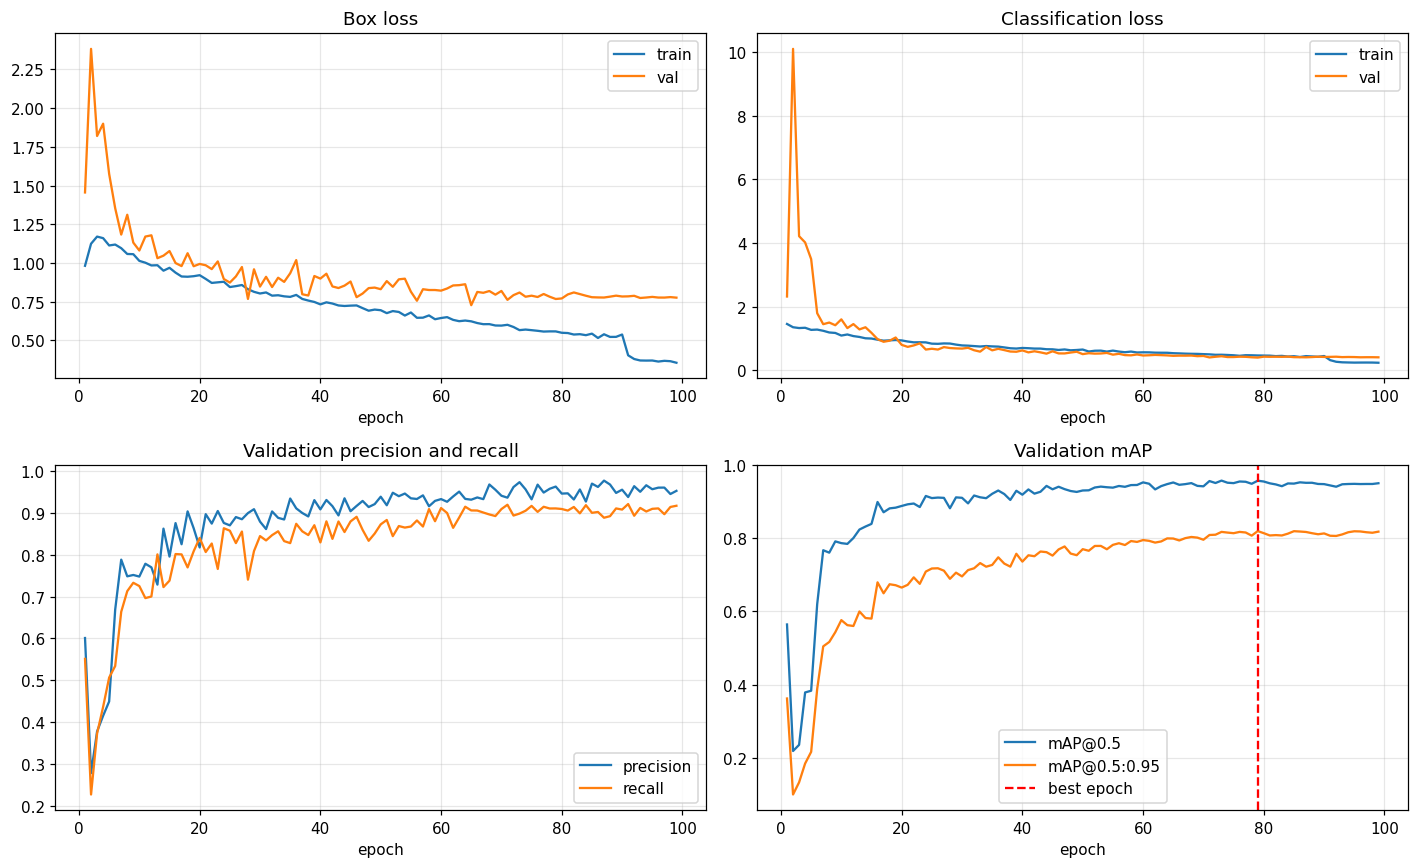

In [ ]:
hist = pd.read_csv(SAVE_DIR/'results.csv'); hist.columns = [c.strip() for c in hist.columns]
best_ep = int(hist.loc[hist['metrics/mAP50-95(B)'].idxmax(), 'epoch'])
show_cols = ['epoch', 'train/box_loss', 'train/cls_loss', 'val/box_loss', 'val/cls_loss',
             'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']
display(hist[show_cols].tail(10).round(4).set_index('epoch'))
print("Epochs trained:", int(hist['epoch'].max()), "| Best epoch:", best_ep, "| Best mAP50-95:", round(hist['metrics/mAP50-95(B)'].max(), 4))
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for col, lab in [('train/box_loss', 'train'), ('val/box_loss', 'val')]: ax[0, 0].plot(hist['epoch'], hist[col], label=lab)
ax[0, 0].set_title('Box loss'); ax[0, 0].legend()
for col, lab in [('train/cls_loss', 'train'), ('val/cls_loss', 'val')]: ax[0, 1].plot(hist['epoch'], hist[col], label=lab)
ax[0, 1].set_title('Classification loss'); ax[0, 1].legend()
for col, lab in [('metrics/precision(B)', 'precision'), ('metrics/recall(B)', 'recall')]: ax[1, 0].plot(hist['epoch'], hist[col], label=lab)
ax[1, 0].set_title('Validation precision and recall'); ax[1, 0].legend()
for col, lab in [('metrics/mAP50(B)', 'mAP@0.5'), ('metrics/mAP50-95(B)', 'mAP@0.5:0.95')]: ax[1, 1].plot(hist['epoch'], hist[col], label=lab)
ax[1, 1].axvline(best_ep, color='red', ls='--', label='best epoch'); ax[1, 1].set_title('Validation mAP'); ax[1, 1].legend()
for a in ax.ravel(): a.set_xlabel('epoch')
plt.tight_layout(); plt.savefig(RES/'training_curves.png', bbox_inches='tight'); plt.show()
hist.to_csv(RES/'training_history.csv', index=False)

## 11. Model summary

In [ ]:
net = best.model
n_params = sum(p.numel() for p in net.parameters())
try:
    from ultralytics.utils.torch_utils import get_flops
    gflops = round(get_flops(net, IMGSZ), 1)
except Exception:
    gflops = float('nan')
summary = pd.DataFrame({'value': {'Architecture': 'YOLO11m', 'Layers': len(net.model), 'Parameters (millions)': round(n_params/1e6, 2),
                                  'GFLOPs at 640px': gflops, 'Weights file (MB)': round(os.path.getsize(BEST)/1e6, 1),
                                  'Input size': f'{IMGSZ} x {IMGSZ}', 'Number of classes': len(NAMES), 'Classes': ', '.join(NAMES.values())}})
display(summary)
layer_counts = pd.Series(Counter(type(m).__name__ for m in net.model)).sort_values(ascending=False).rename('count')
display(layer_counts.to_frame())
summary.to_csv(RES/'model_summary.csv')

,value
Architecture,YOLO11m
Layers,24
Parameters (millions),20.06
GFLOPs at 640px,68.3
Weights file (MB),40.5
Input size,640 x 640
Number of classes,4
Classes,"buffalo, elephant, rhino, zebra"


,count
C3k2,8
Conv,7
Concat,4
Upsample,2
SPPF,1
C2PSA,1
Detect,1


## 12. Validation and test metrics

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,033,116 parameters, 0 gradients, 67.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 19.6±8.1 MB/s, size: 38.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/datasets/african-wildlife/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 62.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.5it/s 6.0s
                   all        225        379       0.96      0.912      0.957      0.811
Speed: 0.8ms preprocess, 21.4ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,033,116 parameters, 0 gra

,Precision,Recall,mAP50,mAP50-95
Validation set,0.9595,0.9123,0.9572,0.8114
Test set,0.9715,0.9340,0.9763,0.8454


,AP50,AP50-95
class,,
buffalo,0.9714,0.8694
elephant,0.9785,0.7988
rhino,0.9919,0.9208
zebra,0.9634,0.7927


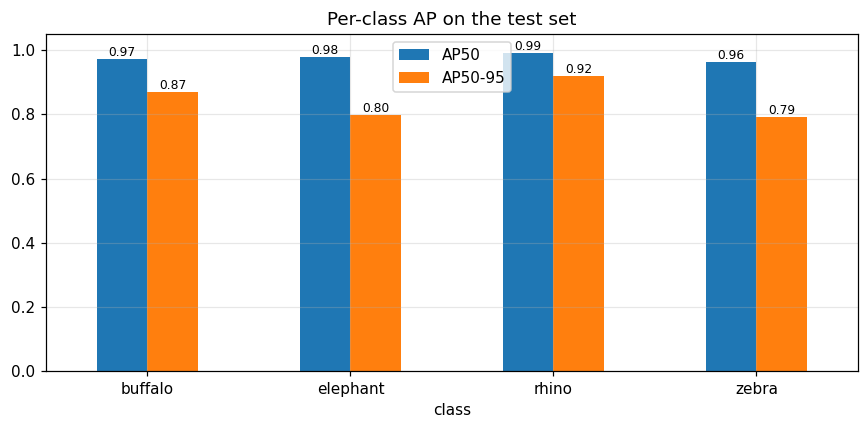

In [ ]:
def row(m): return {'Precision': m.box.mp, 'Recall': m.box.mr, 'mAP50': m.box.map50, 'mAP50-95': m.box.map}
mv = best.val(data=DATA, split="val", imgsz=IMGSZ, conf=0.001, iou=0.6, plots=False, verbose=False)
mt = best.val(data=DATA, split="test", imgsz=IMGSZ, conf=0.001, iou=0.6, plots=False, verbose=False)
main = pd.DataFrame({'Validation set': row(mv), 'Test set': row(mt)}).T.round(4)
display(main); main.to_csv(RES/'main_results.csv')
pc = pd.DataFrame({'class': [NAMES[int(c)] for c in mt.box.ap_class_index], 'AP50': mt.box.ap50,
                   'AP50-95': [mt.box.maps[int(c)] for c in mt.box.ap_class_index]}).set_index('class').round(4)
display(pc); pc.to_csv(RES/'per_class_results.csv')
ax = pc.plot(kind='bar', figsize=(8, 4), rot=0); ax.set_title('Per-class AP on the test set'); ax.set_ylim(0, 1.05)
for p_ in ax.patches: ax.annotate(f'{p_.get_height():.2f}', (p_.get_x()+p_.get_width()/2, p_.get_height()), ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.savefig(RES/'per_class_ap.png', bbox_inches='tight'); plt.show()

## 13. Predictions cache and confidence threshold

,precision,recall,F1
confidence,,,
0.05,0.738,0.950,0.830
0.10,0.805,0.947,0.870
0.15,0.844,0.942,0.890
0.20,0.864,0.939,0.900
0.25,0.885,0.934,0.909
0.30,0.898,0.929,0.913
0.35,0.906,0.921,0.914
0.40,0.916,0.916,0.916
0.45,0.928,0.916,0.922


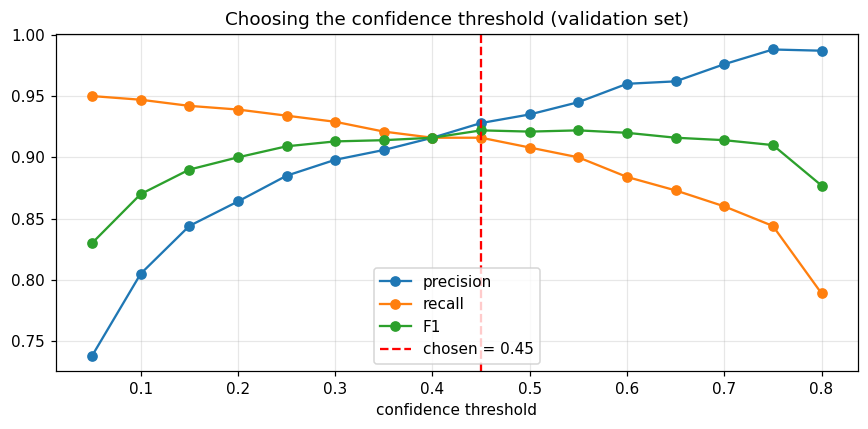

Chosen confidence threshold: 0.45


In [ ]:
ft_fn = make_fn(best)
TEST_PRED = {ip: ft_fn(ip) for ip in IMGS['test']}
VAL_PRED = {ip: ft_fn(ip) for ip in IMGS['val']}
sweep = []
for th in np.arange(0.05, 0.85, 0.05):
    TP = FP = FN = 0
    for ip in IMGS['val']:
        tp, fp, fn = match(GT[ip], [q for q in VAL_PRED[ip] if q[1] >= th]); TP += len(tp); FP += len(fp); FN += len(fn)
    p_, r_ = TP/max(TP+FP, 1), TP/max(TP+FN, 1); sweep.append((round(th, 2), p_, r_, 2*p_*r_/max(p_+r_, 1e-9)))
sw = pd.DataFrame(sweep, columns=['confidence', 'precision', 'recall', 'F1']).round(3)
BEST_CONF = float(sw.loc[sw['F1'].idxmax(), 'confidence'])
display(sw.set_index('confidence'))
plt.figure(figsize=(8, 4))
for col in ['precision', 'recall', 'F1']: plt.plot(sw['confidence'], sw[col], marker='o', label=col)
plt.axvline(BEST_CONF, color='red', ls='--', label=f'chosen = {BEST_CONF}'); plt.xlabel('confidence threshold'); plt.legend(); plt.title('Choosing the confidence threshold (validation set)')
plt.tight_layout(); plt.savefig(RES/'confidence_sweep.png', bbox_inches='tight'); plt.show()
print("Chosen confidence threshold:", BEST_CONF)

## 14. Confusion matrix (test set)

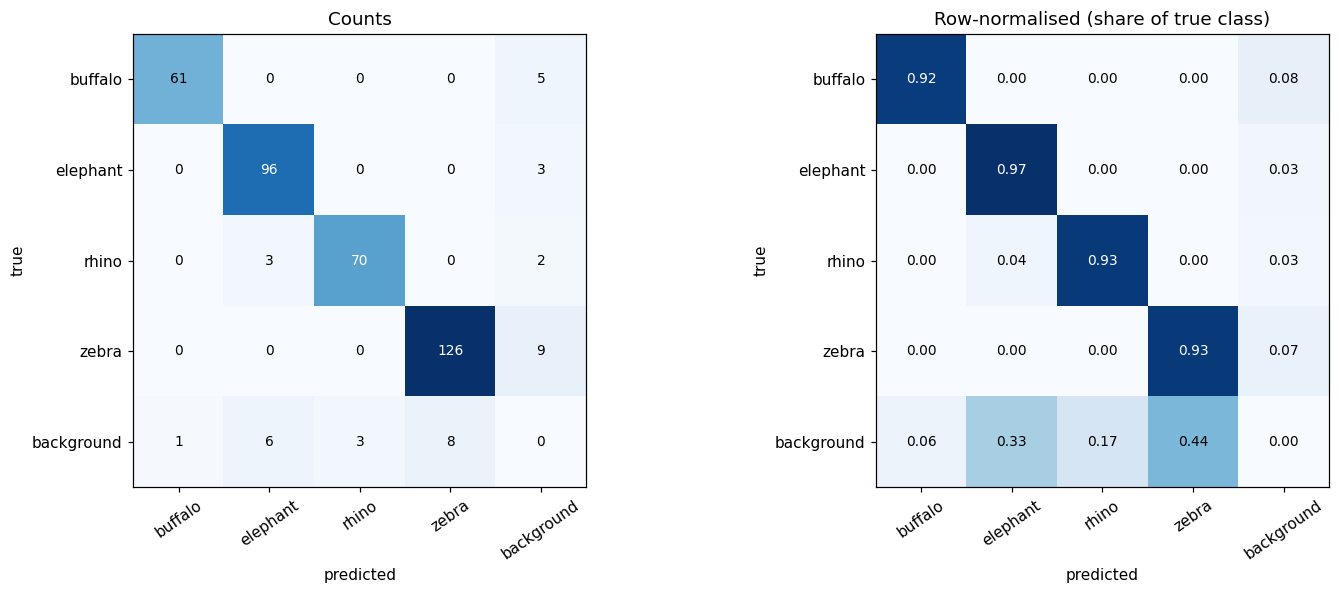

In [ ]:
cm = confusion(TEST_PRED, IMGS['test'], BEST_CONF)
labels = [NAMES[i] for i in CLASS_IDS] + ['background']
cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, M, title, fmt in [(ax[0], cm, 'Counts', '{:d}'), (ax[1], cmn, 'Row-normalised (share of true class)', '{:.2f}')]:
    a.imshow(M, cmap='Blues'); a.set_xticks(range(len(labels))); a.set_yticks(range(len(labels)))
    a.set_xticklabels(labels, rotation=35); a.set_yticklabels(labels); a.set_xlabel('predicted'); a.set_ylabel('true'); a.set_title(title); a.grid(False)
    for i in range(len(labels)):
        for j in range(len(labels)):
            a.text(j, i, fmt.format(M[i, j]), ha='center', va='center', color='white' if M[i, j] > M.max()/2 else 'black', fontsize=9)
plt.tight_layout(); plt.savefig(RES/'confusion_matrix.png', bbox_inches='tight'); plt.show()
pd.DataFrame(cm, index=['true ' + l for l in labels], columns=['pred ' + l for l in labels]).to_csv(RES/'confusion_matrix.csv')

## 15. Per-class precision, recall and F1

In [ ]:
rep = []
for c in CLASS_IDS:
    TP = FP = FN = 0
    for ip in IMGS['test']:
        tp, fp, fn = match([g for g in GT[ip] if g[0] == c], [q for q in TEST_PRED[ip] if q[0] == c and q[1] >= BEST_CONF])
        TP += len(tp); FP += len(fp); FN += len(fn)
    p_, r_ = TP/max(TP+FP, 1), TP/max(TP+FN, 1)
    rep.append({'class': NAMES[c], 'precision': p_, 'recall': r_, 'F1': 2*p_*r_/max(p_+r_, 1e-9), 'support': TP+FN, 'TP': TP, 'FP': FP, 'FN': FN})
rep = pd.DataFrame(rep).set_index('class')
macro = rep[['precision', 'recall', 'F1']].mean(); w = rep['support']/rep['support'].sum()
rep.loc['macro average'] = [*macro, rep['support'].sum(), rep['TP'].sum(), rep['FP'].sum(), rep['FN'].sum()]
rep.loc['weighted average'] = [*(rep.loc[[NAMES[i] for i in CLASS_IDS], ['precision', 'recall', 'F1']].mul(w.values, axis=0).sum()), rep['support'].iloc[:len(CLASS_IDS)].sum(), '', '', '']
display(rep.round(3)); rep.to_csv(RES/'classification_report.csv')

,precision,recall,F1,support,TP,FP,FN
class,,,,,,,
buffalo,0.984,0.924,0.953,66.0,61.0,1.0,5.0
elephant,0.914,0.970,0.941,99.0,96.0,9.0,3.0
rhino,0.973,0.947,0.959,75.0,71.0,2.0,4.0
zebra,0.940,0.933,0.937,135.0,126.0,8.0,9.0
macro average,0.953,0.943,0.948,375.0,354.0,20.0,21.0
weighted average,0.948,0.944,0.945,375.0,,,


## 16. Precision-recall and F1-confidence curves

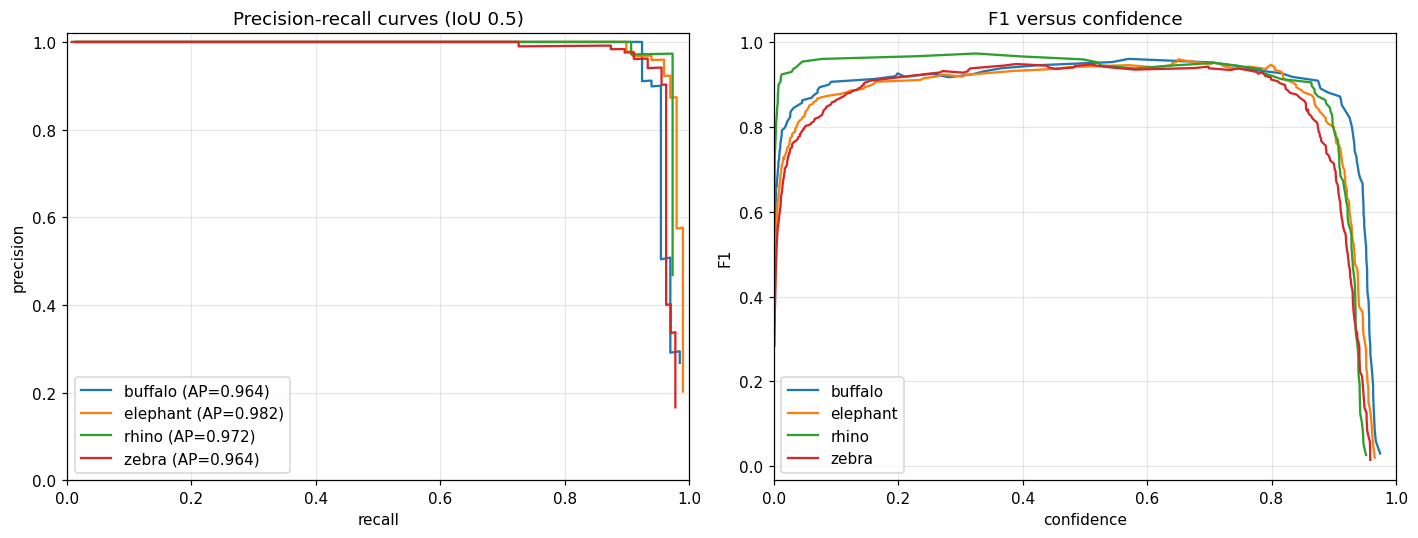

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in CLASS_IDS:
    rec, ngt = records_for(TEST_PRED, IMGS['test'], c); conf_, P, R = pr_arrays(rec, ngt)
    ax[0].plot(R, P, label=f'{NAMES[c]} (AP={average_precision(P, R):.3f})')
    ax[1].plot(conf_, 2*P*R/np.maximum(P+R, 1e-9), label=NAMES[c])
ax[0].set_xlabel('recall'); ax[0].set_ylabel('precision'); ax[0].set_title('Precision-recall curves (IoU 0.5)'); ax[0].legend(); ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1.02)
ax[1].set_xlabel('confidence'); ax[1].set_ylabel('F1'); ax[1].set_title('F1 versus confidence'); ax[1].legend(); ax[1].set_xlim(0, 1)
plt.tight_layout(); plt.savefig(RES/'pr_and_f1_curves.png', bbox_inches='tight'); plt.show()

## 17. Localisation quality at stricter IoU thresholds

,IoU 0.5,IoU 0.6,IoU 0.7,IoU 0.8,IoU 0.9
buffalo,0.964,0.964,0.932,0.872,0.797
elephant,0.982,0.982,0.957,0.836,0.482
rhino,0.972,0.972,0.972,0.972,0.871
zebra,0.964,0.956,0.930,0.835,0.518
mean (mAP),0.970,0.968,0.948,0.879,0.667


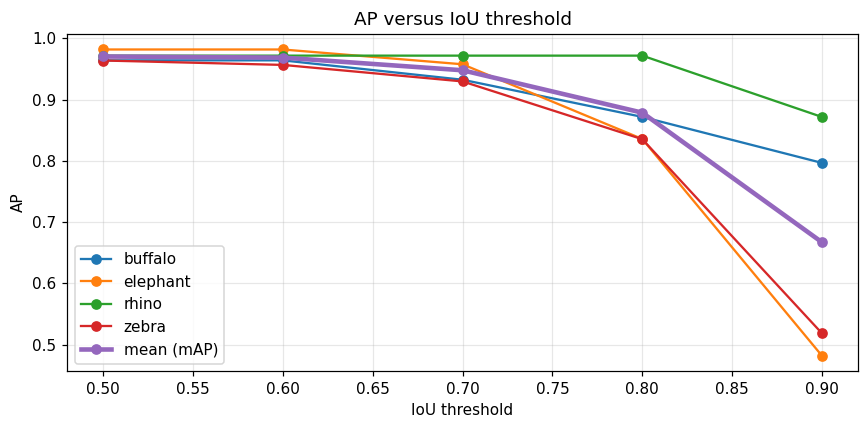

In [ ]:
thrs = [0.5, 0.6, 0.7, 0.8, 0.9]
iou_df = pd.DataFrame({t: {NAMES[c]: ap_for(TEST_PRED, IMGS['test'], c, t) for c in CLASS_IDS} for t in thrs})
iou_df.loc['mean (mAP)'] = iou_df.mean(); iou_df.columns = [f'IoU {t}' for t in thrs]
display(iou_df.round(3)); iou_df.to_csv(RES/'ap_vs_iou.csv')
plt.figure(figsize=(8, 4))
for name in iou_df.index: plt.plot(thrs, iou_df.loc[name], marker='o', lw=3 if name.startswith('mean') else 1.5, label=name)
plt.xlabel('IoU threshold'); plt.ylabel('AP'); plt.title('AP versus IoU threshold'); plt.legend(); plt.tight_layout()
plt.savefig(RES/'ap_vs_iou.png', bbox_inches='tight'); plt.show()

## 18. Performance by animal size

,animals,found,recall
size,,,
small,56,48,0.857
medium,151,143,0.947
large,168,163,0.970


size,small,medium,large
class,,,
buffalo,0.333,0.909,0.976
elephant,0.950,0.943,1.000
rhino,0.800,0.963,0.953
zebra,0.857,0.955,0.950


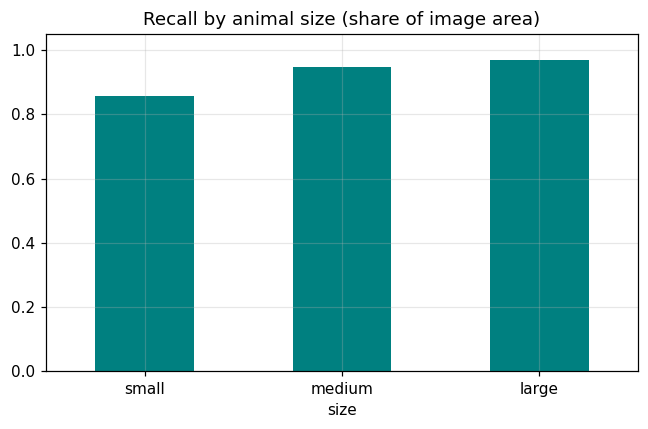

In [ ]:
size_rows = []
for ip in IMGS['test']:
    W, H = SIZES[ip]; gt = GT[ip]
    tp, fp, fn = match(gt, [q for q in TEST_PRED[ip] if q[1] >= BEST_CONF]); fn_ids = {id(g) for g in fn}
    for g in gt:
        size_rows.append({'class': NAMES[g[0]], 'size': size_cat((g[3]-g[1])*(g[4]-g[2])/(W*H)), 'found': id(g) not in fn_ids})
sz = pd.DataFrame(size_rows)
by_size = sz.groupby('size')['found'].agg(['count', 'sum']).reindex(['small', 'medium', 'large']).dropna()
by_size['recall'] = (by_size['sum']/by_size['count']).round(3); by_size.columns = ['animals', 'found', 'recall']
display(by_size)
pivot = sz.pivot_table(index='class', columns='size', values='found', aggfunc='mean').reindex(columns=['small', 'medium', 'large']).round(3)
display(pivot)
ax = by_size['recall'].plot(kind='bar', figsize=(6, 4), rot=0, color='teal'); ax.set_ylim(0, 1.05); ax.set_title('Recall by animal size (share of image area)')
plt.tight_layout(); plt.savefig(RES/'recall_by_size.png', bbox_inches='tight'); plt.show()
by_size.to_csv(RES/'recall_by_size.csv')

## 19. Performance by number of animals in the image

,images,animals,TP,FP,recall,precision
group,,,,,,
1 animal,136,136,134,5,0.985,0.964
2-3 animals,80,177,166,12,0.938,0.933
4+ animals,11,62,54,3,0.871,0.947


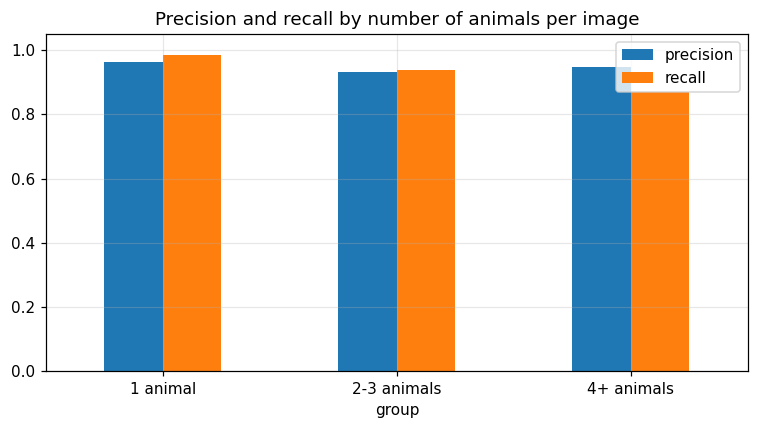

In [ ]:
crowd_rows = []
for ip in IMGS['test']:
    n = len(GT[ip])
    if n == 0: continue
    tp, fp, fn = match(GT[ip], [q for q in TEST_PRED[ip] if q[1] >= BEST_CONF])
    crowd_rows.append({'group': '1 animal' if n == 1 else '2-3 animals' if n <= 3 else '4+ animals', 'GT': n, 'TP': len(tp), 'FP': len(fp)})
cr = pd.DataFrame(crowd_rows).groupby('group').agg(images=('GT', 'size'), animals=('GT', 'sum'), TP=('TP', 'sum'), FP=('FP', 'sum'))
cr = cr.reindex(['1 animal', '2-3 animals', '4+ animals']).dropna()
cr['recall'] = (cr['TP']/cr['animals']).round(3); cr['precision'] = (cr['TP']/(cr['TP']+cr['FP']).clip(lower=1)).round(3)
display(cr); cr.to_csv(RES/'performance_by_crowding.csv')
ax = cr[['precision', 'recall']].plot(kind='bar', figsize=(7, 4), rot=0); ax.set_ylim(0, 1.05); ax.set_title('Precision and recall by number of animals per image')
plt.tight_layout(); plt.savefig(RES/'performance_by_crowding.png', bbox_inches='tight'); plt.show()

## 20. Confidence of correct and incorrect detections

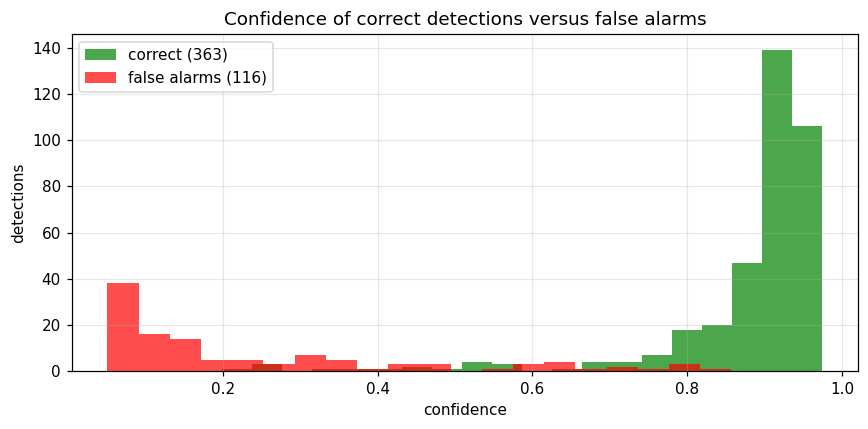

,count,mean confidence,median confidence
correct,363,0.881,0.919
false alarm,116,0.237,0.143


In [ ]:
tp_conf, fp_conf = [], []
for ip in IMGS['test']:
    tp, fp, _ = match(GT[ip], [q for q in TEST_PRED[ip] if q[1] >= 0.05]); tp_conf += [q[1] for q in tp]; fp_conf += [q[1] for q in fp]
plt.figure(figsize=(8, 4))
plt.hist(tp_conf, bins=20, alpha=0.7, label=f'correct ({len(tp_conf)})', color='green'); plt.hist(fp_conf, bins=20, alpha=0.7, label=f'false alarms ({len(fp_conf)})', color='red')
plt.xlabel('confidence'); plt.ylabel('detections'); plt.title('Confidence of correct detections versus false alarms'); plt.legend()
plt.tight_layout(); plt.savefig(RES/'confidence_histogram.png', bbox_inches='tight'); plt.show()
display(pd.DataFrame({'count': [len(tp_conf), len(fp_conf)], 'mean confidence': [np.mean(tp_conf), np.mean(fp_conf) if fp_conf else 0],
                      'median confidence': [np.median(tp_conf), np.median(fp_conf) if fp_conf else 0]}, index=['correct', 'false alarm']).round(3))

## 21. Inference speed

In [ ]:
sample = IMGS['test'][:50]
best.predict(sample[0], imgsz=IMGSZ, conf=BEST_CONF, verbose=False)
speeds = pd.DataFrame([best.predict(ip, imgsz=IMGSZ, conf=BEST_CONF, verbose=False)[0].speed for ip in sample])
speed_summary = speeds.mean().round(2).rename('ms per image').to_frame()
speed_summary.loc['total'] = speed_summary['ms per image'].sum()
fps = 1000/speed_summary.loc['total', 'ms per image']
display(speed_summary); print("Throughput:", round(fps, 1), "images per second")
speed_summary.to_csv(RES/'inference_speed.csv')

,ms per image
preprocess,2.14
inference,20.64
postprocess,1.92
total,24.70


Throughput: 40.5 images per second


## 22. Baseline versus fine-tuned model

,Baseline AP50,Fine-tuned AP50,Improvement
buffalo,0.000,0.964,0.964
elephant,0.821,0.982,0.161
rhino,0.000,0.972,0.972
zebra,0.985,0.964,-0.021
mean,0.452,0.970,0.519


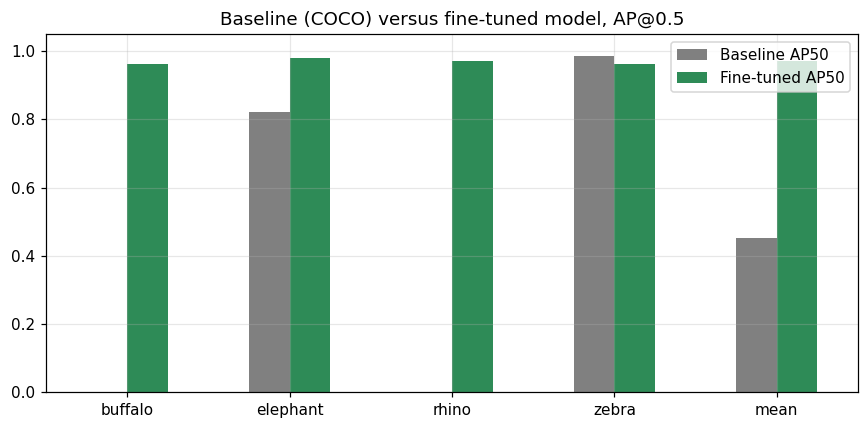

In [ ]:
cmp_rows = {}
for c in CLASS_IDS:
    n = NAMES[c]
    cmp_rows[n] = {'Baseline AP50': base_df.loc[n, 'AP50'] if n in base_df.index else 0.0, 'Fine-tuned AP50': ap_for(TEST_PRED, IMGS['test'], c)}
cmp_df = pd.DataFrame(cmp_rows).T; cmp_df['Improvement'] = cmp_df['Fine-tuned AP50'] - cmp_df['Baseline AP50']
cmp_df.loc['mean'] = cmp_df.mean()
display(cmp_df.round(3)); cmp_df.to_csv(RES/'baseline_vs_finetuned.csv')
ax = cmp_df[['Baseline AP50', 'Fine-tuned AP50']].plot(kind='bar', figsize=(8, 4), rot=0, color=['gray', 'seagreen']); ax.set_ylim(0, 1.05)
ax.set_title('Baseline (COCO) versus fine-tuned model, AP@0.5')
plt.tight_layout(); plt.savefig(RES/'baseline_vs_finetuned.png', bbox_inches='tight'); plt.show()

## 23. Engineered test sets

In [ ]:
rng = np.random.default_rng(SEED)
def low_light(im):   return np.clip(255*((im/255.0)**2.2)*0.7, 0, 255).astype(np.uint8)
def overexposed(im): return np.clip(im.astype(np.float32)*1.6 + 40, 0, 255).astype(np.uint8)
def blur(im):        return cv2.GaussianBlur(im, (0, 0), 4)
def motion(im):
    k = np.zeros((17, 17)); k[8, :] = 1/17
    return cv2.filter2D(im, -1, k)
def noise(im):       return np.clip(im.astype(np.float32) + rng.normal(0, 25, im.shape), 0, 255).astype(np.uint8)
def low_res(im):
    h, w = im.shape[:2]
    return cv2.resize(cv2.resize(im, (max(1, w//4), max(1, h//4))), (w, h))
def occlusion(im):
    im = im.copy(); h, w = im.shape[:2]
    for _ in range(3):
        bw, bh = int(w*rng.uniform(.08, .18)), int(h*rng.uniform(.08, .18))
        x, y = int(rng.uniform(0, w-bw)), int(rng.uniform(0, h-bh)); im[y:y+bh, x:x+bw] = 90
    return im
CONDS = {'low_light': low_light, 'overexposed': overexposed, 'blur': blur, 'motion_blur': motion,
         'noise': noise, 'low_res': low_res, 'occlusion': occlusion}

ENG = Path('/content/engineered'); shutil.rmtree(ENG, ignore_errors=True); eng_yaml = {}
for cname, f in CONDS.items():
    (ENG/cname/'images').mkdir(parents=True); (ENG/cname/'labels').mkdir(parents=True)
    for ip in IMGS['test']:
        cv2.imwrite(str(ENG/cname/'images'/(Path(ip).stem + '.jpg')), f(cv2.imread(ip)), [cv2.IMWRITE_JPEG_QUALITY, 95])
        if os.path.exists(label_path(ip)): shutil.copy(label_path(ip), ENG/cname/'labels'/(Path(ip).stem + '.txt'))
    y = ENG/f'{cname}.yaml'
    y.write_text(f"path: {ENG/cname}\ntrain: images\nval: images\nnames:\n" + ''.join(f"  {i}: {n}\n" for i, n in NAMES.items()))
    eng_yaml[cname] = str(y)

ex = IMGS['test'][0]
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
axs[0, 0].imshow(cv2.imread(ex)[..., ::-1]); axs[0, 0].set_title('original')
for a, (cname, f) in zip(axs.ravel()[1:], CONDS.items()):
    a.imshow(f(cv2.imread(ex))[..., ::-1]); a.set_title(cname)
for a in axs.ravel(): a.axis('off')
plt.tight_layout(); plt.savefig(RES/'engineered_examples.png', bbox_inches='tight'); plt.show()

## 24. Robustness results

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,033,116 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1391.4±861.0 MB/s, size: 70.7 KB)
val: Scanning /content/engineered/low_light/labels... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 1.9Kit/s 0.1s
val: New cache created: /content/engineered/low_light/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.5it/s 6.0s
                   all        227        375      0.941      0.908      0.953      0.809
Speed: 0.9ms preprocess, 21.0ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,033,116 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2181.2±681.7 MB/s, size: 136.7

,Precision,Recall,mAP50,mAP50-95,mAP50 drop vs clean
clean (original test),0.972,0.934,0.976,0.845,0.000
low_light,0.941,0.908,0.953,0.809,0.023
overexposed,0.983,0.889,0.964,0.816,0.012
blur,0.887,0.691,0.782,0.632,0.194
motion_blur,0.953,0.669,0.787,0.606,0.189
noise,0.951,0.864,0.936,0.780,0.041
low_res,0.894,0.824,0.896,0.746,0.080
occlusion,0.953,0.892,0.950,0.799,0.026


Most damaging condition: blur | Least damaging condition: overexposed | Average mAP50 drop: 0.081


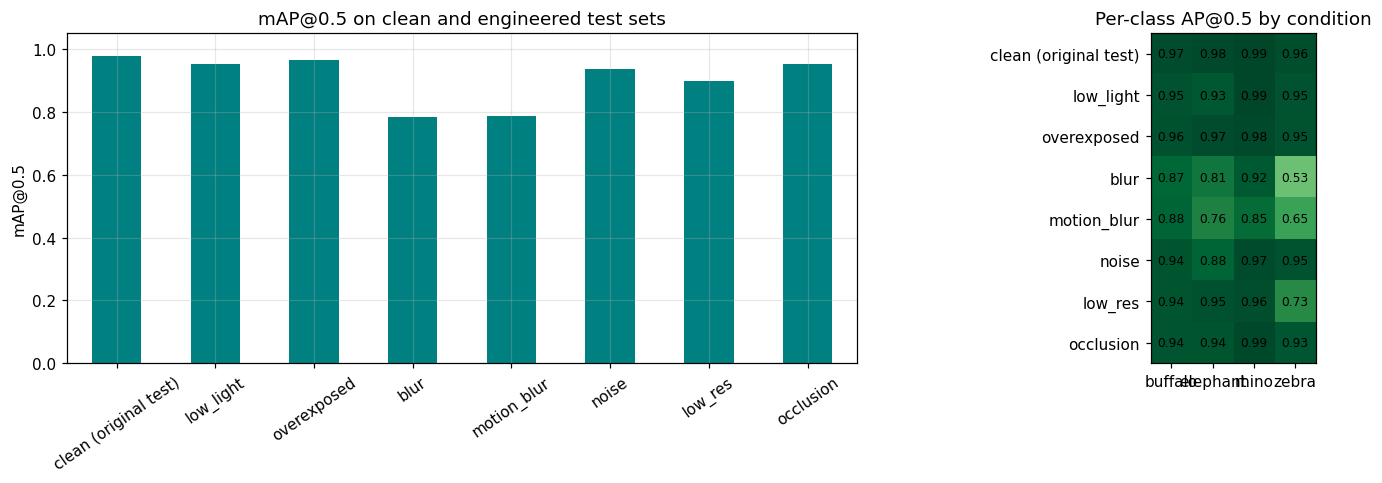

In [ ]:
eng = {'clean (original test)': row(mt)}; eng_cls = {'clean (original test)': {NAMES[int(c)]: a for c, a in zip(mt.box.ap_class_index, mt.box.ap50)}}
for cname, y in eng_yaml.items():
    m_ = best.val(data=y, split='val', imgsz=IMGSZ, conf=0.001, iou=0.6, plots=False, verbose=False)
    eng[cname] = row(m_); eng_cls[cname] = {NAMES[int(c)]: a for c, a in zip(m_.box.ap_class_index, m_.box.ap50)}
eng = pd.DataFrame(eng).T; eng['mAP50 drop vs clean'] = eng['mAP50'].iloc[0] - eng['mAP50']
display(eng.round(3)); eng.round(4).to_csv(RES/'engineered_test_results.csv')
worst_c = eng['mAP50'].iloc[1:].idxmin(); best_c = eng['mAP50'].iloc[1:].idxmax()
print("Most damaging condition:", worst_c, "| Least damaging condition:", best_c, "| Average mAP50 drop:", round(eng['mAP50 drop vs clean'].iloc[1:].mean(), 3))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
eng['mAP50'].plot(kind='bar', ax=ax[0], color='teal', rot=35); ax[0].set_ylabel('mAP@0.5'); ax[0].set_title('mAP@0.5 on clean and engineered test sets'); ax[0].set_ylim(0, 1.05)
hm = pd.DataFrame(eng_cls).T[[NAMES[i] for i in CLASS_IDS]]
ax[1].imshow(hm.values, cmap='YlGn', vmin=0, vmax=1); ax[1].set_xticks(range(hm.shape[1])); ax[1].set_xticklabels(hm.columns); ax[1].set_yticks(range(hm.shape[0])); ax[1].set_yticklabels(hm.index)
ax[1].set_title('Per-class AP@0.5 by condition'); ax[1].grid(False)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): ax[1].text(j, i, f'{hm.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.tight_layout(); plt.savefig(RES/'engineered_robustness.png', bbox_inches='tight'); plt.show()

## 25. Error breakdown

,count,share (%)
Correct detection,354,89.6
Wrong species,3,0.8
Poor box / duplicate,8,2.0
False alarm (background),9,2.3
Missed animal,21,5.3


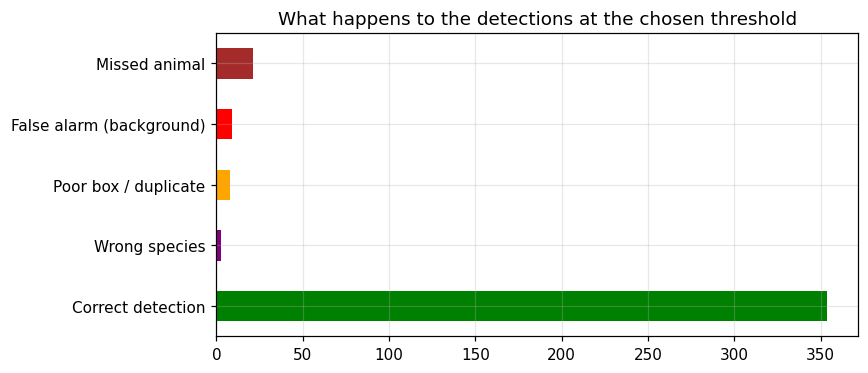

In [ ]:
et = pd.Series(error_types(TEST_PRED, IMGS['test'], BEST_CONF), name='count').to_frame()
et['share (%)'] = (100*et['count']/et['count'].sum()).round(1)
display(et); et.to_csv(RES/'error_breakdown.csv')
ax = et['count'].plot(kind='barh', figsize=(8, 3.5), color=['green', 'purple', 'orange', 'red', 'brown']); ax.set_title('What happens to the detections at the chosen threshold')
plt.tight_layout(); plt.savefig(RES/'error_breakdown.png', bbox_inches='tight'); plt.show()

## 26. Hardest and best test images

In [ ]:
def draw_errors(ip, conf):
    im = cv2.imread(ip); H, W = im.shape[:2]; t = max(2, W//300); fs = max(0.6, W/1000)
    tp, fp, fn = match(GT[ip], [q for q in TEST_PRED[ip] if q[1] >= conf])
    for lst, col in [(tp, (0, 200, 0)), (fp, (0, 0, 255))]:
        for q in lst:
            cv2.rectangle(im, (int(q[2]), int(q[3])), (int(q[4]), int(q[5])), col, t)
            cv2.putText(im, f'{NAMES[q[0]]} {q[1]:.2f}', (int(q[2]), max(18, int(q[3])-8)), cv2.FONT_HERSHEY_SIMPLEX, fs, col, t)
    for g in fn:
        cv2.rectangle(im, (int(g[1]), int(g[2])), (int(g[3]), int(g[4])), (0, 140, 255), t+1)
        cv2.putText(im, 'MISSED ' + NAMES[g[0]], (int(g[1]), max(18, int(g[2])-8)), cv2.FONT_HERSHEY_SIMPLEX, fs, (0, 140, 255), t)
    return im[..., ::-1], len(fp), len(fn)

scored = []
for ip in IMGS['test']:
    _, nfp, nfn = draw_errors(ip, BEST_CONF); scored.append((ip, nfp, nfn))
worst = sorted(scored, key=lambda t: -(t[1]+t[2]))[:6]
good = sorted(scored, key=lambda t: (t[1]+t[2]))[:3]
fig, axs = plt.subplots(3, 3, figsize=(16, 12))
for a, (ip, nfp, nfn) in zip(axs.ravel(), worst + good):
    a.imshow(draw_errors(ip, BEST_CONF)[0]); a.set_title(f"false alarms={nfp}  missed={nfn}", fontsize=10); a.axis('off')
plt.tight_layout(); plt.savefig(RES/'error_gallery.png', bbox_inches='tight'); plt.show()
print("Test images with no errors:", sum(1 for t in scored if t[1] + t[2] == 0), "of", len(scored))

## 27. Example predictions for every species

In [ ]:
fig, axs = plt.subplots(len(CLASS_IDS), 2, figsize=(12, 4*len(CLASS_IDS)))
for r_, c in enumerate(CLASS_IDS):
    cand = [ip for ip in IMGS['test'] if any(g[0] == c for g in GT[ip])]
    for a, ip in zip(axs[r_], random.sample(cand, min(2, len(cand)))):
        a.imshow(best.predict(ip, conf=BEST_CONF, imgsz=IMGSZ, iou=0.6, verbose=False)[0].plot()[..., ::-1]); a.axis('off'); a.set_title(f'test image containing {NAMES[c]}')
plt.tight_layout(); plt.savefig(RES/'predictions_per_species.png', bbox_inches='tight'); plt.show()

## 28. Final project summary

In [ ]:
final = pd.DataFrame({'value': {
    'Dataset': 'African Wildlife (Ultralytics)', 'Total images': int(total['images']), 'Classes': len(NAMES),
    'Model': 'YOLO11m (COCO-pretrained, fine-tuned)', 'Parameters (millions)': round(n_params/1e6, 2),
    'Epochs trained': int(hist['epoch'].max()), 'Best epoch': best_ep,
    'Test precision': round(main.loc['Test set', 'Precision'], 3), 'Test recall': round(main.loc['Test set', 'Recall'], 3),
    'Test mAP@0.5': round(main.loc['Test set', 'mAP50'], 3), 'Test mAP@0.5:0.95': round(main.loc['Test set', 'mAP50-95'], 3),
    'Chosen confidence threshold': BEST_CONF, 'Macro F1 at that threshold': round(rep.loc['macro average', 'F1'], 3),
    'Baseline mean AP@0.5 (COCO, 4 classes)': round(cmp_df.loc[[NAMES[i] for i in CLASS_IDS], 'Baseline AP50'].mean(), 3),
    'Fine-tuned mean AP@0.5': round(cmp_df.loc[[NAMES[i] for i in CLASS_IDS], 'Fine-tuned AP50'].mean(), 3),
    'Most damaging degradation': worst_c, 'Average mAP drop under degradation': round(eng['mAP50 drop vs clean'].iloc[1:].mean(), 3),
    'Inference speed (images/s)': round(fps, 1)}})
display(final); final.to_csv(RES/'final_summary.csv')

,value
Dataset,African Wildlife (Ultralytics)
Total images,1504
Classes,4
Model,"YOLO11m (COCO-pretrained, fine-tuned)"
Parameters (millions),20.06
Epochs trained,99
Best epoch,79
Test precision,0.972
Test recall,0.934
Test mAP@0.5,0.976


## 29. Save results

In [ ]:
shutil.copytree(SAVE_DIR, RES/'training_run', dirs_exist_ok=True)
zip_path = shutil.make_archive('/content/wildlife_results', 'zip', RES)
print("Saved:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("Download failed:", e)

Saved: /content/wildlife_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 30. Live demo

In [ ]:
import gradio as gr

def analyse(img_bgr, conf, imgsz=IMGSZ, tta=False):
    try: r = best.predict(img_bgr, conf=conf, imgsz=imgsz, iou=0.6, augment=tta, verbose=False)[0]
    except Exception: r = best.predict(img_bgr, conf=conf, imgsz=imgsz, iou=0.6, verbose=False)[0]
    counts = {n: 0 for n in NAMES.values()}
    for c in r.boxes.cls: counts[NAMES[int(c)]] += 1
    return r.plot(), counts

def demo_fn(img, conf, imgsz, tta):
    if img is None: return None, "Upload a photo first."
    vis, counts = analyse(cv2.cvtColor(img, cv2.COLOR_RGB2BGR), conf, int(imgsz), tta)
    total_ = sum(counts.values())
    txt = "No buffalo, elephant, rhino or zebra detected." if total_ == 0 else f"Total animals: {total_}\n" + "\n".join(f"{k}: {v}" for k, v in counts.items() if v)
    return vis[..., ::-1], txt

gr.Interface(demo_fn,
    [gr.Image(type='numpy', label='Photo', sources=['upload', 'webcam']),
     gr.Slider(0.05, 0.9, BEST_CONF, step=0.05, label='Confidence threshold'),
     gr.Radio([640, 800, 960], value=640, label='Image size'),
     gr.Checkbox(False, label='Test-time augmentation')],
    [gr.Image(label='Detections'), gr.Textbox(label='Animals found', lines=5)],
    title='WildSight - African Wildlife Detector').launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5dff567630be6d7331.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
